# <span style="color:blue;font-weight:bold;font-size:1.1em">S07: ANOVA</span>

The $t$-test was a great step forward in both statistics and science bringing a robust test to scientists which would work well even for small sample sizes.

The only problem was that the $t$-test could only compare and contrast **2 or fewer samples**. For situations where the grouping variable had 3 or more levels (freshman, sophomore, junior, senior), the $t$-test would not work.
<br><br><br>
Ron Fisher took up the challenge and created the mathematical extension of the $t$-test for use with more than 2 groups. His statistical test is called **ANOVA** which stands for <span style = 'color:red;font-weight:bold'>Analysis of Variance</span>.

## <span style="color:blue;font-weight:bold;font-size:1.1em">Conducting the ANOVA in R</span>
**Example.** Test whether the variable GPA varies based upon year in school (Yr).

We proceed through the following steps:
- Create the Model
   $$\text{mod = lm(GPA $\sim$ Yr, data = pers)}$$

- Extract the Residuals
   $$\text{res = residuals(mod)}$$

- Produce a QQ plot of the Residuals (as we did with linear regression)

- If the Data are Appropriate, Run the ANOVA
   $$\text{anova = aov(GPA $\sim$ Yr, data = pers)}$$

- <span style = 'color:blue;font-weight:bold'>Only if we reject the null, conduct a *post hoc* </span><span style = 'color:red;font-weight:bold'>Tukey HSD</span>
   $$\text{TukeyHSD(anova)}$$

## Getting Started

Let's load some data frames for our examples.

In [5]:
pers <- read.csv('https://faculty.ung.edu/rsinn/data/personality.csv')
city <- read.csv('https://faculty.ung.edu/rsinn/data/worldcity.csv')

## Example 1: Perfectionism

Test whether levels of perfectionism vary depending upon whether one prefers to sit in the front, middle, or back of the classroom using the **Perf** and **SitClass** columns of the personality data frame. Test at the $\alpha = 0.05$ level.

### Hypothesis

- $H_0 : \mu_f = \mu_m = \mu_b$
- $H_a : $ At least one of the group means is significantly different than the others.

### Data Verification

In [6]:
mod <- lm(Perf ~ SitClass, data = pers)
res <- residuals(mod)

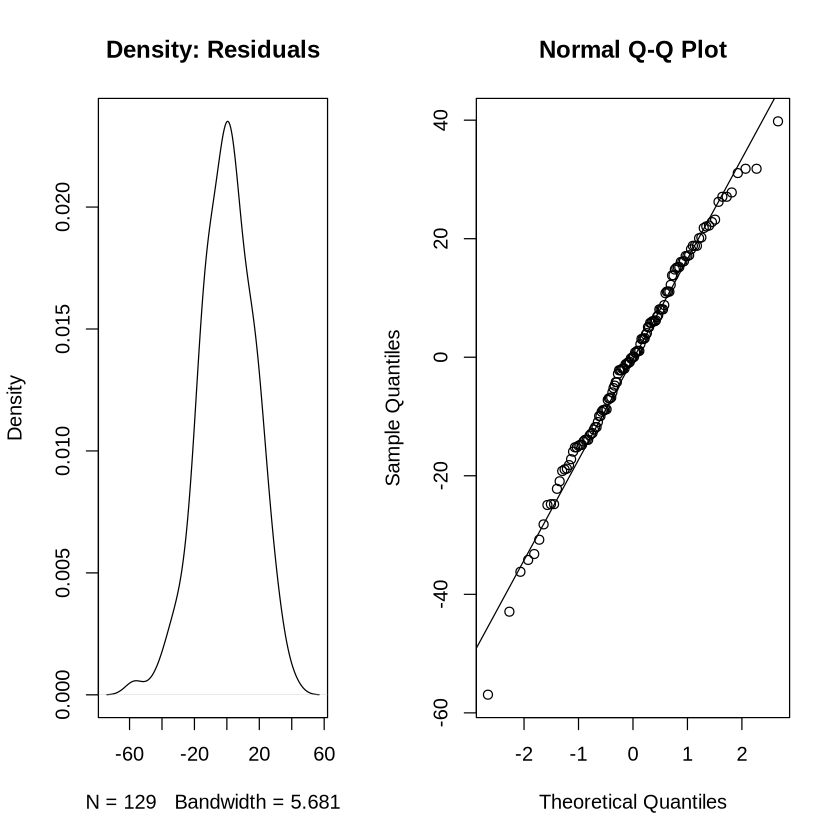

In [7]:
layout(matrix(c(1,2), ncol =2), lcm(8))
plot(density(res), main = 'Density: Residuals')
plt <- { qqnorm(res)
        qqline(res)}

### Data Verification Results

These data are appropriate for ANOVA procedures. The QQ plot is extremely close to linear with only slight heavy tails while the density plot shows normality.

In [8]:
anova <- aov(Perf ~ SitClass, data = pers)
summary(anova)

             Df Sum Sq Mean Sq F value Pr(>F)  
SitClass      2   2452  1225.8   4.334 0.0151 *
Residuals   126  35636   282.8                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

### Reporting Out

We reject the null due to the fact that $p = 0.0151 < 0.05 = \alpha$. Hence, at least one of these group means is different than the others.

Therefore, we will conduct a post hoc Tukey HSD.

In [9]:
TukeyHSD(anova)

  Tukey multiple comparisons of means
    95% family-wise confidence level

Fit: aov(formula = Perf ~ SitClass, data = pers)

$SitClass
         diff         lwr        upr     p adj
F-B 10.414286   0.8136784 20.0148931 0.0300489
M-B  2.142857  -7.0890019 11.3747162 0.8464019
M-F -8.271429 -16.2565765 -0.2862806 0.0404878


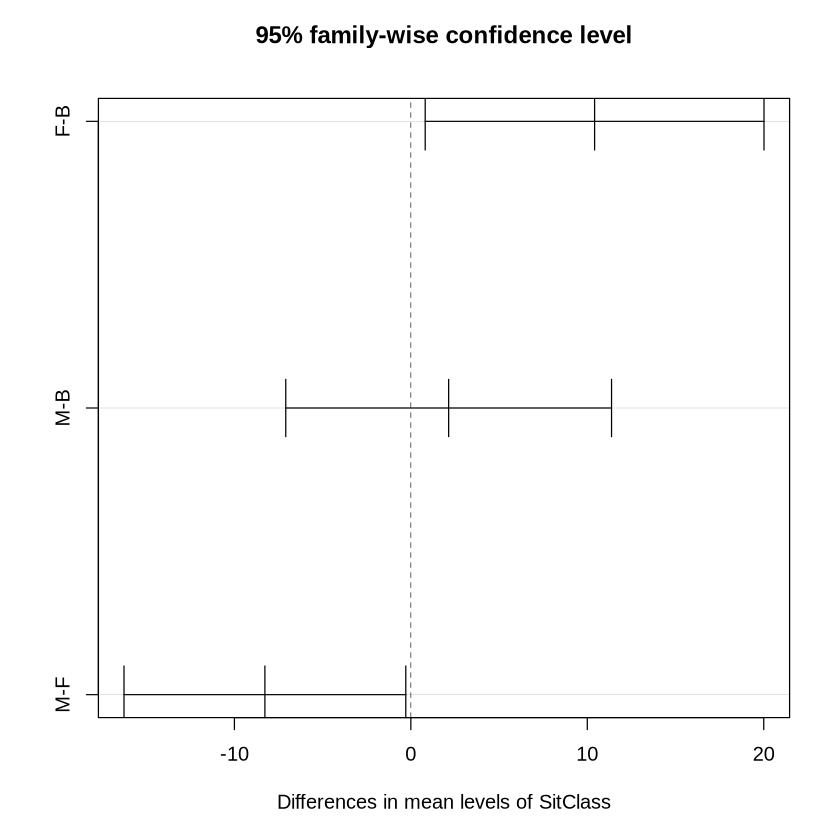

In [10]:
plot(TukeyHSD(anova))

### Reporting Out

The honestly significant differences exist between the Front vs. Back group and the Front vs. Middle group.

## Example 2: Optimism and Humor

Test whether <span style = 'color:blue'>optimism scores</span> vary based upon <span style = 'color:blue'>primary humor style</span> at the $\alpha = 0.05$ level. We will use the **CHS** and **PHS** variables in the personality data frame.

### Hypothesis

- $H_0 : \mu_{af} = \mu_{ag} = \mu_{sd} =\mu_{se}$
- $H_0 : \$ At least one of the group means is significantly different from the others.

### Data Verification

In [11]:
layout(matrix(c(1,2), ncol=2))

### Data Verificaiton Results

...

## Run the ANOVA

### Reporting Out



### Post Hoc Tukey HSD

If needed ...

### Reporting Out

...

## Example 3: Cities and Population

The **city** data frame lists the populations of the largest cities in the world. Test whether there is a difference in population averages between China, India, Brazil and Japan at the $\alpha = 0.05$ level.

In [13]:
data <- subset(city, country == 'China' | country == 'India' | country == 'Brazil' | country == 'Japan',
               select = c(1,4,5))
head(data)

,city,country,population
,<chr>,<chr>,<dbl>
1,Tokyo,Japan,37977000
3,Delhi,India,29617000
4,Mumbai,India,23355000
6,Shanghai,China,22120000
7,Sao Paulo,Brazil,22046000
10,Guangzhou,China,20902000


### Hypothesis

- $H_0 : \mu_{c} = \mu_{b} = \mu_{j} =\mu_{i}$
- $H_0 : \$ At least one of the group means is significantly different from the others.

### Data Verification

In [14]:
mod3 <- lm(population ~ country, data = city)
res3 <- residuals(mod3)

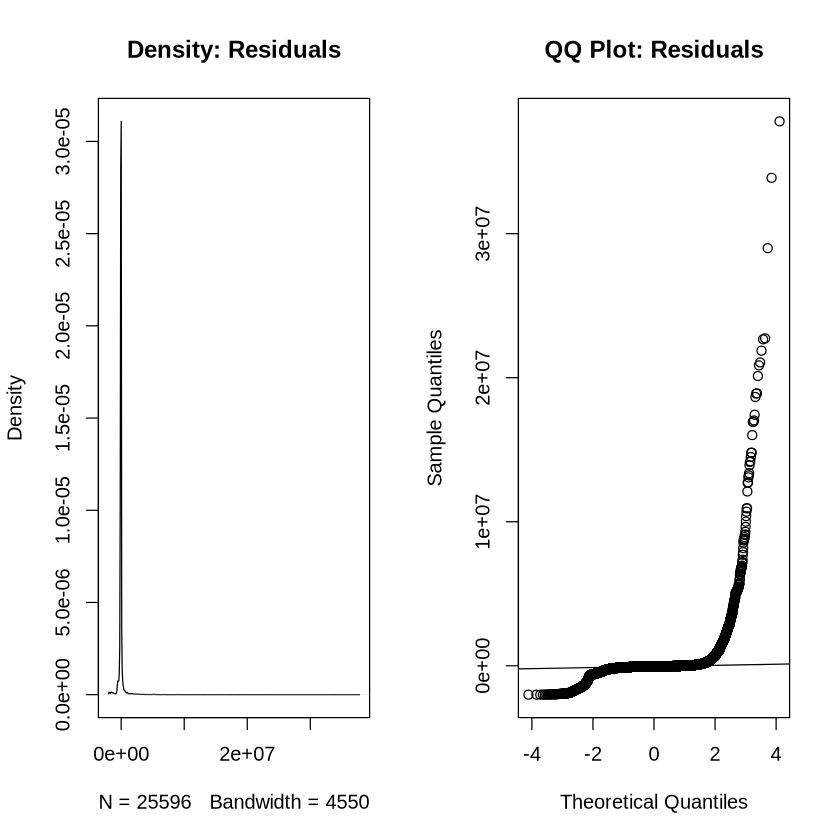

In [15]:
layout(matrix(c(1,2), ncol=2))
plot(density(res3), main = 'Density: Residuals')
plt3 <- {
    qqnorm(res3, main = 'QQ Plot: Residuals')
    qqline(res3)
}

### Data Verification Results

These data **are not appropriate** for ANOVA procedures.